# fedOPD — build the canonical table

Transformation only. Reads the 96 validated monthly RTT extracts and produces **one** tidy table at **provider × department × month**, plus the rectangular panel the federation trains on.

Run after `02_inspect_dataset.ipynb`, which establishes the facts relied on here.

## What this builds

**19 series per provider:** the 18 named specialties that span all 96 months, plus `X_OTHER`, a merged residual worth about a quarter of demand.

**All providers retained**, trust and independent alike, with a `sector` column. Sector filtering is a downstream one-line panel decision, never baked in here.

**15 columns out of 121.** A raw column is kept only if some part of the README's system consumes it. The column contract, and the measurement justifying every drop, is the section before the outputs.

## The two era reconciliations

NHS England changed the return in April 2021 in two independent ways, both the same shape — coarse before, finer after. Both reconcile to the **coarser** form, because the early era cannot be disaggregated.

| | pre-2021 | post-2021 | reconciled to |
|---|---|---|---|
| Long waits | single `Gt 52 Weeks` column | weekly bands 52→104 plus `Gt 104` | one `>52` figure |
| Residual specialties | single `X01 Other` | five buckets `X02`–`X06` | one `X_OTHER` series |

Columns are chosen **by name with an explicit era branch**, never by position.

## Standing asserts

Every trap found during inspection fails loudly here rather than silently:

1. **Full-coverage identity** — 18 named + `X_OTHER` = `C_999`, per provider, part type and month.
2. **Boundary continuity at 2021-04** — measured against *local* variation, not global.
3. **Code-only joins** — treatment functions keyed on code; names changed at the break, codes did not.
4. **Key uniqueness** — one row per provider × department × month.
5. **Hierarchy completeness** — every panel trust resolves to an ICB, so escalation has a target.
6. **Round trip** — the written parquet reads back with the same shape and a real datetime index.

In [1]:
import re                             # regex: reads the month out of a filename and the lower edge out of a band name
from pathlib import Path                # portable path objects
from datetime import datetime           # real dates, so months sort chronologically
import pandas as pd                     # the table library; this notebook is one long chain of DataFrame ops
import matplotlib.pyplot as plt         # the two continuity plots

DATA = Path("../data")
RTT_CSV = DATA / "rtt_csv"                        # the 96 validated monthly files
REF = DATA / "reference"                          # census + lookups from inspect_dataset
OUT = DATA / "canonical"                          # everything this notebook produces
OUT.mkdir(parents=True, exist_ok=True)            # no-op if it already exists

AGG = "C_999"                                     # published aggregate row — never a department
OTHER = "X_OTHER"                                 # our merged residual series
ERA = datetime(2021, 4, 1)                        # first month of the post-change schema

MONTHS = "JANUARY FEBRUARY MARCH APRIL MAY JUNE JULY AUGUST SEPTEMBER OCTOBER NOVEMBER DECEMBER".split()

def month_of(name):
    """'RTT-OCTOBER-2019-full-extract.csv' -> datetime(2019, 10, 1)."""
    m = re.search(r"(" + "|".join(MONTHS) + r")-(\d{4})", name.upper())   # month word + year
    return datetime(int(m.group(2)), MONTHS.index(m.group(1)) + 1, 1)     # index+1 = month number

csvs = sorted(RTT_CSV.glob("*.csv"), key=lambda p: month_of(p.name))      # chronological order
census = pd.read_csv(REF / "provider_census.csv")                        # built by inspect_dataset
SECTOR = dict(zip(census.code, census.sector))                           # code -> public/independent
ICB = dict(zip(census.code, census.icb_parent))                          # code -> ICB where one exists
PANEL = set(census[census.panel_member].code)                         # census column name, unchanged
print(f"{len(csvs)} monthly files | {len(census)} providers | {len(PANEL)} panel trusts")

96 monthly files | 653 providers | 126 panel trusts


## Helpers

Four small functions carry every era-dependent decision, so the branch lives in one visible place instead of being scattered through the build.

In [2]:
def week_of(col):
    """Lower edge of a band column. 'Gt 18 To 19 Weeks SUM 1' -> 18, 'Gt 104 Weeks SUM 1' -> 104."""
    return int(re.match(r"Gt (\d+)", col).group(1))           # the first number in the name

def bands_from(cols, lo):
    """Band columns at or above `lo` weeks, selected BY NAME so both eras work unchanged:
       pre-2021,  lo=52 -> ['Gt 52 Weeks SUM 1']           the single open-ended bucket
       post-2021, lo=52 -> ['Gt 52 To 53', ..., 'Gt 104']  weekly bands plus the tail
       The 18-52 bands are identical in both eras, so lo=18 needs no branch at all."""
    return [c for c in cols if "Weeks SUM" in c               # waiting-time band columns only
            and week_of(c) >= lo]                             # at or above the threshold

def dept_of(code):
    """Treatment-function code -> series name. X01..X06 all collapse into one residual."""
    return OTHER if str(code).startswith("X") else code       # named specialties pass through

def header_of(path):
    """Column names of a csv, without reading the body."""
    return open(path, newline="").readline().rstrip("\r\n").replace('"', "").split(",")

# print what the rule selects in each era, so the branch is visible rather than implied
for label, f in [("pre-2021", csvs[0]), ("post-2021", csvs[-1])]:
    cols = header_of(f)                                       # this month's schema
    g52 = bands_from(cols, 52)                                # the era-dependent set
    print(f"{label:10s} >18 uses {len(bands_from(cols, 18)):3d} cols | "
          f">52 uses {len(g52):3d} cols -> {g52[0]}{' ... ' + g52[-1] if len(g52) > 1 else ''}")

pre-2021   >18 uses  35 cols | >52 uses   1 cols -> Gt 52 Weeks SUM 1
post-2021  >18 uses  87 cols | >52 uses  53 cols -> Gt 52 To 53 Weeks SUM 1 ... Gt 104 Weeks SUM 1


## The build pass

One read of all 96 files. Band columns are read **only for `Part_2`**, the waiting list — the only part type whose long-wait detail is used. Reading bands for the other four would multiply the IO for columns we then discard.

This is the slow cell.

In [3]:
KEYS = ["Provider Org Code", "Provider Org Name", "Provider Parent Org Code",
        "Commissioner Parent Org Code",                                # for own-ICB share only
        "RTT Part Type", "Treatment Function Code", "Total All"]       # always needed

totals, longwaits, coverage, ownicb = [], [], [], []   # small frames per month, concatenated after
reporting = []                                         # which part types each provider filed each month
for p in csvs:
    mth = month_of(p.name)                        # this file's month
    cols = header_of(p)                           # this file's schema, 69 or 121 columns
    g18 = bands_from(cols, 18)                    # >18w columns, era-stable
    g52 = bands_from(cols, 52)                    # >52w columns, era-dependent
    d = pd.read_csv(p, usecols=lambda c: c in set(KEYS) | set(g18), low_memory=False)

    # --- coverage input: set the published C_999 rows aside, then drop them from the data ---
    is_agg = d["Treatment Function Code"].eq(AGG)                      # the aggregate rows
    published = (d[is_agg].groupby(["Provider Org Code", "RTT Part Type"])["Total All"]
                          .sum().rename("published"))                  # what NHS says the total is
    d = d[~is_agg].copy()                                              # real specialties only
    d["dept"] = d["Treatment Function Code"].map(dept_of)              # X01..X06 -> X_OTHER

    ours = (d.groupby(["Provider Org Code", "RTT Part Type"])["Total All"]
             .sum().rename("ours"))                                    # what our 19 series sum to
    chk = pd.concat([published, ours], axis=1).fillna(0).reset_index()
    chk["month"] = mth
    coverage.append(chk)                                               # checked by Assert 1

    # --- own-ICB share: does a trust's own ICB commission the work it delivers? ---------------
    # Only meaningful from Apr 2021, when the stated provider parent is reliably an ICB rather
    # than an NHS region (F-20). Kept as a per-provider attribute, never collapsed away silently.
    if mth >= ERA:
        dem = d[d["RTT Part Type"] == "Part_3"]                        # new referrals only
        own = dem["Commissioner Parent Org Code"].eq(dem["Provider Parent Org Code"])
        ownicb.append(pd.DataFrame({
            "provider_code": dem["Provider Org Code"],
            "own": dem["Total All"].where(own, 0),                     # referrals from own ICB
            "all": dem["Total All"],
        }).groupby("provider_code").sum().reset_index())

    # --- reporting flag: which part types did this provider actually FILE this month? -------
    # A provider that stops submitting files NO rows, not rows of zero, so a panel zero can mean
    # 'did not report'. Partial returns happen too, so one boolean is not enough.
    # crosstab counts rows per (provider, part type); > 0 = that part type is present this month.
    rep = (pd.crosstab(d['Provider Org Code'], d['RTT Part Type']) > 0).reset_index()
    rep['month'] = mth                                                 # tag with the month
    reporting.append(rep)                                              # one frame per month

    # --- headline totals: one value per provider x dept x part type ---
    t = (d.groupby(["Provider Org Code", "Provider Org Name",
                    "Provider Parent Org Code", "dept", "RTT Part Type"])["Total All"]
          .sum().rename("total").reset_index())
    t["month"] = mth
    totals.append(t)

    # --- long waits: Part_2 only, because only the waiting list needs band detail ---
    w = d[d["RTT Part Type"] == "Part_2"]                              # incomplete pathways
    lw = pd.DataFrame({
        "Provider Org Code": w["Provider Org Code"],
        "dept": w["dept"],
        "waiting_gt18": w[g18].fillna(0).sum(axis=1),                  # sum the >=18w bands
        "waiting_gt52": w[g52].fillna(0).sum(axis=1),                  # era-reconciled >=52w
    })
    lw = lw.groupby(["Provider Org Code", "dept"]).sum().reset_index() # collapse to the key
    lw["month"] = mth
    longwaits.append(lw)

totals = pd.concat(totals, ignore_index=True)                          # one row per part type
longwaits = pd.concat(longwaits, ignore_index=True)
coverage = pd.concat(coverage, ignore_index=True)
reporting = pd.concat(reporting, ignore_index=True).fillna(False)      # absent part type = False
own_share = pd.concat(ownicb, ignore_index=True).groupby("provider_code").sum()
own_share = (own_share["own"] / own_share["all"] * 100).rename("own_icb_share")   # percent
print(f"{len(totals):,} provider x dept x part x month rows | {len(longwaits):,} long-wait rows")
print(f"own-ICB share computed for {len(own_share):,} providers over the post-{ERA:%Y-%m} months")
print(f"reporting matrix: {len(reporting):,} provider x month rows")

1,421,475 provider x dept x part x month rows | 317,768 long-wait rows
own-ICB share computed for 598 providers over the post-2021-04 months
reporting matrix: 42,542 provider x month rows


## Reporting completeness - which provider-months are absent, not zero

A provider that suspends its return files **no rows**. Reindexing the panel then turns that absence
into a zero, and a zero is indistinguishable from "this service saw nobody this month" unless the
distinction is carried explicitly.

This is not a COVID-only problem and not a rare one. NHS names the non-submitters in each month's
statistical press notice, and the policy behind it is formal: suspending submission *"needs to be a
decision taken and owned by the board of a provider"*, and the trust *"will be highlighted in any
national publications as not being able to submit data"* [G section 10.3, p.50].

Known cases, from the NHS sources rather than from this data: Barnsley (RFF) and Royal Free London
(RAL) filed nothing for July 2020; Bradford (RAE) filed incomplete-pathway data but no completed
pathways and no new RTT periods in the same month; Frimley Health (RDU) and Manchester University
(R0A) filed nothing for October and November 2022, R0A again in December 2022; Sheffield (RHQ) filed
nothing for March 2026.

The cell below measures how many provider-months are affected in our own data, and separates
**complete** returns from **partial** ones.

In [4]:
PARTS = ["Part_1A", "Part_1B", "Part_2", "Part_2A", "Part_3"]     # the five sections of the return
present = [p for p in PARTS if p in reporting.columns]           # defensive only in the sense of era
reporting["n_parts"] = reporting[present].sum(axis=1)            # how many of the five were filed
reporting["reported_demand"] = reporting["Part_3"]               # did they file NEW RTT PERIODS?
reporting["reported_full"] = reporting["n_parts"].eq(len(present))   # all five sections present

# every provider x month combination that COULD have existed, for providers seen at least once
seen = reporting.groupby("Provider Org Code")["month"].agg(["min", "max"])   # first and last month
all_months = sorted(reporting.month.unique())                    # the 96 reporting periods

# a provider-month is a GAP if it falls inside that provider's own active span but has no rows:
# absence outside the span is an organisation that did not exist yet or had closed, which is a
# different thing entirely and must not be counted as a failure to report
filed = set(zip(reporting["Provider Org Code"], reporting["month"]))   # what actually appears
gaps = [(c, m) for c, (lo, hi) in seen.iterrows()                # for each provider's own window
        for m in all_months if lo <= m <= hi and (c, m) not in filed]

print(f"provider x month returns filed      : {len(reporting):,}")
print(f"  all five part types present       : {int(reporting.reported_full.sum()):,}")
print(f"  partial returns (1-4 part types)   : {int((~reporting.reported_full).sum()):,}")
print(f"  filed something but NOT Part_3     : {int((~reporting.reported_demand).sum()):,}")
print(f"gaps inside a provider's own span    : {len(gaps):,}")

# the named cases from the NHS press notices, checked against our own files rather than assumed
print("\nNHS-named non-submissions, verified against our data:")
for code, ym in [("RFF", "2020-07"), ("RAL", "2020-07"), ("RAE", "2020-07"),
                 ("RDU", "2022-10"), ("R0A", "2022-11"), ("RHQ", "2026-03")]:
    m = pd.Timestamp(ym + "-01")                                 # the month in question
    row = reporting[(reporting["Provider Org Code"] == code) & (reporting.month == m)]
    if len(row) == 0:
        print(f"  {code} {ym}: NO ROWS AT ALL - full non-submission")
    else:
        got = [p for p in present if bool(row.iloc[0][p])]       # which sections they did file
        print(f"  {code} {ym}: filed {got}")

provider x month returns filed      : 42,542


  all five part types present       : 35,634
  partial returns (1-4 part types)   : 6,908
  filed something but NOT Part_3     : 504
gaps inside a provider's own span    : 393

NHS-named non-submissions, verified against our data:
  RFF 2020-07: NO ROWS AT ALL - full non-submission
  RAL 2020-07: NO ROWS AT ALL - full non-submission
  RAE 2020-07: filed ['Part_2', 'Part_2A']
  RDU 2022-10: NO ROWS AT ALL - full non-submission
  R0A 2022-11: NO ROWS AT ALL - full non-submission
  RHQ 2026-03: NO ROWS AT ALL - full non-submission


## Assert 1 — full-coverage identity

18 named + `X_OTHER` must equal the published `C_999`, for every provider, part type and month. Stronger than the roster-drift check in `02_inspect_dataset.ipynb`: it proves the 19 series account for **all** reported activity, so the hierarchy reconciles exactly rather than approximately.

In [5]:
coverage["diff"] = coverage["ours"] - coverage["published"]    # zero everywhere if coverage is total
bad = coverage[coverage["diff"].abs() > 0.5]                   # tolerance for float noise only
print(f"groups compared : {len(coverage):,}")
print(f"mismatched      : {len(bad)}")
if len(bad):
    print(bad.head(15).to_string(index=False))                 # show exactly what broke
assert len(bad) == 0, "the 19 series do not reproduce C_999 — coverage is incomplete"
print("\nASSERT 1 PASSED: 18 named + X_OTHER = C_999 everywhere. Coverage is total.")

groups compared : 199,410
mismatched      : 0

ASSERT 1 PASSED: 18 named + X_OTHER = C_999 everywhere. Coverage is total.


## Assemble the canonical table

Pivot the five part types into columns, attach the long-wait detail, then the census flags.

In [6]:
IDX = ["month", "Provider Org Code", "Provider Org Name", "Provider Parent Org Code", "dept"]

# pivot_table reshapes long -> wide: the five part types stop being rows and become five measures
# on one key. fill_value=0 means 'no activity reported' - a modelling choice, not formatting.
wide = totals.pivot_table(index=IDX, columns="RTT Part Type", values="total",
                          fill_value=0).reset_index()
wide.columns.name = None                                       # drop the pivot's column-axis label

canon = wide.rename(columns={
    "Provider Org Code": "provider_code",
    "Provider Org Name": "provider_name",
    "Provider Parent Org Code": "icb_reported",                 # parent as stated in the RTT file
    "Part_3": "demand",                                         # new RTT periods = demand signal
    "Part_1A": "completed_admitted",                            # completed pathways, admitted
    "Part_1B": "completed_nonadmitted",                         # completed pathways, non-admitted
    "Part_2": "waiting",                                        # incomplete pathways = waiting list
    "Part_2A": "waiting_dta",                                   # of those, with a decision to admit
})

# attach >18w / >52w detail; how="left" keeps every canonical row, and rows with no matching
# long-wait record come back NaN, which means zero long waits
canon = canon.merge(longwaits.rename(columns={"Provider Org Code": "provider_code"}),
                    on=["month", "provider_code", "dept"], how="left")
canon[["waiting_gt18", "waiting_gt52"]] = canon[["waiting_gt18", "waiting_gt52"]].fillna(0)

canon["completed"] = canon.completed_admitted + canon.completed_nonadmitted   # total throughput
canon["sector"] = canon.provider_code.map(SECTOR)               # public / independent
canon["icb_ods"] = canon.provider_code.map(ICB)                 # ODS RE5 parent, time-invariant

# --- the escalation key -------------------------------------------------------------------
# `icb_reported` is not usable: it names NHS REGIONS pre-2020 and ICBs after. `icb_ods` is one
# fixed ICB per trust, so that is the key. Where ODS has no answer, fall back to the provider's
# most recent post-2021 reported parent, and only if that code is a known ICB - one value per
# provider, never a region code.
VALID_ICB = set(pd.Series(list(ICB.values())).dropna())        # every ICB ODS actually resolved
recent = canon[canon.month >= ERA].sort_values("month")        # post-schema-break months only
fallback = recent.groupby("provider_code")["icb_reported"].last()
fallback = fallback[fallback.isin(VALID_ICB)]                  # region codes are refused here

canon["icb"] = canon.icb_ods                                   # authoritative where ODS resolved it
gap = canon.sector.eq("public") & canon.icb.isna()             # public providers ODS could not place
canon.loc[gap, "icb"] = canon.loc[gap, "provider_code"].map(fallback)
filled = canon.loc[gap & canon.icb.notna(), "provider_code"].nunique()
print(f"icb backfilled for {filled} public providers from their latest post-{ERA:%Y-%m} reported "
      f"parent, accepted only where that code is a known ICB; "
      f"{canon[canon.sector.eq('public') & canon.icb.isna()].provider_code.nunique()} public "
      f"providers remain unplaced, independents keep icb = NaN")

# --- the two roles a provider can play, which are NOT the same set -------------------------
# `fl_client` was doing two jobs: "trains the forecaster" and "can receive an allocation".
# They separate on the axis the README already draws — capacity is allocated to NHS trusts and
# purchased from independents — so they are now two flags and neither implies the other.
#
# ELIGIBILITY, widened 2026-07-27. `fl_client` was the balanced panel: public and present in ALL
# 96 months, which is 126 trusts. Measured, that rule discards 20% of public demand, because a
# trust that merged into its current form in 2020 fails it while running a full service today.
# The rule is now: public, still reporting in the final month, and at least MIN_MONTHS of demand
# history to window on. A trust that has stopped reporting is excluded on purpose — capacity
# cannot be allocated to a hospital that no longer files.
MIN_MONTHS = 48                                                 # 4 years; enough for a 24-month lookback
demand_months = (canon[canon.sector.eq("public") & canon.demand.gt(0)]
                 .groupby("provider_code").month.agg(["nunique", "max"]))
eligible = set(demand_months[(demand_months["nunique"] >= MIN_MONTHS)
                             & (demand_months["max"] == canon.month.max())].index)

canon["fl_client"] = canon.provider_code.isin(eligible)         # federated training client
canon["allocatable"] = canon.sector.eq("public")                # can receive NHS capacity

# print what widening bought, so the change is a measurement rather than an assertion
pub_demand = canon[canon.sector.eq("public")].demand.sum()
for label, codes in [("balanced panel, all 96 months", PANEL), (f"eligible, >={MIN_MONTHS}mo + active", eligible)]:
    sub = canon[canon.provider_code.isin(codes)]
    series = sub[sub.demand > 0].groupby(["provider_code", "dept"]).ngroups
    print(f"  {label:34s}: {len(codes):3d} trusts | {series:5,d} series | "
          f"{sub.demand.sum() / pub_demand * 100:5.2f}% of public demand")
print(f"  widening adds {len(eligible - PANEL)} trusts and drops {len(PANEL - eligible)}")

canon = canon.sort_values(["provider_code", "dept", "month"]).reset_index(drop=True)

# --- apply the column contract --------------------------------------------------------------
# Everything per-provider rather than per-row resolves ONCE into the dimension table and is
# joined from there. Deriving an organisation-level attribute per row from the monthly files is
# the failure that produced F-11, F-18 and the backfill leak; this is where that stops.
provider_dim = (canon.sort_values("month").groupby("provider_code").agg(
    provider_name=("provider_name", "last"),                    # most recent spelling
    sector=("sector", "first"),
    icb=("icb", "first"),
    icb_ods=("icb_ods", "first"),                               # provenance: what ODS said
    icb_reported_last=("icb_reported", "last"),                 # provenance: what the file said
    fl_client=("fl_client", "first"), allocatable=("allocatable", "first"),
    first_month=("month", "min"), last_month=("month", "max"),
).reset_index())
# how literally the trust -> ICB escalation can be taken, per provider (F-22)
provider_dim["own_icb_share"] = provider_dim.provider_code.map(own_share).round(1)

# keep the month-varying reported parent alive for the contract evidence below, then drop it
icb_audit = canon[["month", "sector", "icb_reported", "icb_ods"]].copy()

KEEP = ["month", "provider_code", "dept", "sector", "icb", "fl_client", "allocatable",
        "demand", "completed_admitted", "completed_nonadmitted", "completed",
        "waiting", "waiting_gt18", "waiting_gt52", "waiting_dta"]
dropped = [c for c in canon.columns if c not in KEEP]
canon = canon[KEEP]
print(f"columns moved to provider_dim / derivable: {dropped}")

# Assert 4 — the key must be unique
dup = int(canon.duplicated(["provider_code", "dept", "month"]).sum())
assert dup == 0, f"{dup} duplicate provider/dept/month rows"
# Assert 5 — every federation client must have somewhere to escalate to
orphan = canon[canon.fl_client & canon.icb.isna()].provider_code.nunique()
assert orphan == 0, f"{orphan} federation clients have no ICB — the hierarchy is broken"
# Assert 6a — icb is TIME-INVARIANT: one value per provider, never drifting mid-window
drift = canon.groupby("provider_code").icb.nunique(dropna=True)
assert drift.max() <= 1, f"{int((drift > 1).sum())} providers change ICB mid-window"
# Assert 6b — and every resolved value is a real ICB. 6a alone would pass if a provider were
# CONSISTENTLY backfilled with a region code, which is precisely the leak that was found.
leaked = sorted(set(canon.icb.dropna()) - VALID_ICB)
assert not leaked, f"non-ICB codes leaked into the escalation key: {leaked}"

print(f"canonical rows : {len(canon):,}  x {len(canon.columns)} columns")
print(f"providers      : {canon.provider_code.nunique()}  "
      f"(fl_client {canon[canon.fl_client].provider_code.nunique()}, "
      f"allocatable {canon[canon.allocatable].provider_code.nunique()})")
print(f"departments    : {canon.dept.nunique()}  (18 named + {OTHER})")
print(f"months         : {canon.month.nunique()}")
print(f"ICBs (key)     : {canon.icb.nunique()} distinct, all valid | clients without an ICB: {orphan}")
canon.head()

icb backfilled for 2 public providers from their latest post-2021-04 reported parent, accepted only where that code is a known ICB; 14 public providers remain unplaced, independents keep icb = NaN
  balanced panel, all 96 months     : 126 trusts | 1,870 series | 80.19% of public demand
  eligible, >=48mo + active         : 150 trusts | 2,198 series | 95.39% of public demand
  widening adds 24 trusts and drops 0


columns moved to provider_dim / derivable: ['provider_name', 'icb_reported', 'icb_ods']
canonical rows : 322,531  x 15 columns
providers      : 653  (fl_client 150, allocatable 196)
departments    : 19  (18 named + X_OTHER)


months         : 96
ICBs (key)     : 36 distinct, all valid | clients without an ICB: 0


,month,provider_code,dept,sector,icb,fl_client,allocatable,demand,completed_admitted,completed_nonadmitted,completed,waiting,waiting_gt18,waiting_gt52,waiting_dta
0,2024-06-01,8KL73,C_301,independent,NaN,False,False,139.0,101.0,0.0,101.0,70.0,0.0,0.0,70.0
1,2024-07-01,8KL73,C_301,independent,NaN,False,False,141.0,130.0,0.0,130.0,55.0,0.0,0.0,55.0
2,2024-08-01,8KL73,C_301,independent,NaN,False,False,122.0,129.0,0.0,129.0,51.0,0.0,0.0,51.0
3,2020-12-01,A0C5S,C_130,independent,NaN,False,False,2.0,0.0,1.0,1.0,7.0,0.0,0.0,0.0
4,2021-01-01,A0C5S,C_130,independent,NaN,False,False,23.0,4.0,5.0,9.0,35.0,0.0,0.0,12.0


## The column contract - which of the 121 raw columns the problem statement actually needs

The raw file is 69 columns before April 2021 and 121 after. The canonical table keeps 15. This
section makes that decision **in code**, so every drop is a measurement rather than an opinion, and
writes the verdict to `data/reference/column_contract.csv`.

Three tests, applied in order. A column has to survive all three.

1. **Is it populated?** A column that is blank, constant, or a rounding-error residual decides
   nothing, whatever it is called.
2. **Is it a label or an axis?** Group by `provider x treatment function x part type` and count
   distinct values. Exactly one value per group means the column is *functionally determined* by keys
   we already carry: it is a **label**, and dropping it loses nothing a join could not restore. More
   than one means a genuine **axis**, and collapsing it discards information that needs justifying
   out loud.
3. **Does the problem statement consume it?** Every kept column must map to a named component of the
   forecaster or the decision layer. If nothing reads it, it is not in the contract.

Test 2 is the sharp one, because it turns "is this redundant?" from a judgement into a query.

The structural tests run on **one post-2021 month**, since column structure is a property of the
schema rather than of a particular month.

In [7]:
SAMPLE = csvs[-1]                                   # one post-2021 month: 121 columns, the wider schema
raw = pd.read_csv(SAMPLE, low_memory=False)         # low_memory=False forces one dtype decision per
                                                    # column over the whole file, not per chunk
KEY = ["Provider Org Code", "Treatment Function Code", "RTT Part Type"]   # the grain we test within

bands = [c for c in raw.columns if "Weeks SUM" in c]      # the waiting-time histogram buckets
plain = [c for c in raw.columns if c not in bands]        # everything else, tested one by one

rows = []                                                 # one verdict per column
for col in plain:
    filled = raw[col].notna().mean()                      # test 1: fraction of rows carrying a value
    per_key = raw.groupby(KEY)[col].nunique()             # test 2: distinct values inside each group
    rows.append({"column": col,
                 "filled": filled,
                 "max_per_key": int(per_key.max()),       # 1 means the key determines the value
                 "kind": "label" if per_key.max() <= 1 else "axis"})
contract = pd.DataFrame(rows)

# Test 2 applies to DESCRIPTIVE columns only. A measure obviously varies inside a key with several
# commissioner rows, so calling it an "axis" is a category error - made once here already.
MEASURES = ["Total", "Total All", "Patients with unknown clock start date"]
contract.loc[contract.column.isin(MEASURES), "kind"] = "measure"

# Test 3: name the consumer. A column is kept only if a named part of the problem statement reads it.
KEEP_WHY = {
    "Provider Org Code":       "federated client id - one silo per trust",
    "Treatment Function Code": "department - one series per client x department",
    "RTT Part Type":           "selects demand / throughput / backlog",
    "Total All":               "the measure itself, and the only one populated for all five parts",
}
DROP_WHY = {
    "Provider Org Name":            "label; names drift while codes do not (F-11). Moved to provider_dim",
    "Provider Parent Org Code":     "not a stable ICB: DCO before Apr-2020, STP after, ICB later. Superseded by the ODS key",
    "Provider Parent Name":         "label for a code we already reject",
    "Commissioner Org Code":        "the one genuine second axis: who PAID, not who delivered. Summed over deliberately",
    "Commissioner Org Name":        "label on that axis",
    "Commissioner Parent Org Code": "same axis at parent level; read only to compute own_icb_share",
    "Commissioner Parent Name":     "label on that axis",
    "RTT Part Description":         "label for RTT Part Type",
    "Treatment Function Name":      "label, renamed for 18 of 24 codes at Apr-2021 (F-11)",
    "Period":                       "the month, already carried as the key",
    "Total":                        "identically zero for Part_2, Part_2A and Part_3, so not universal",
    "Patients with unknown clock start date": "residual already inside Total All",
}
contract["verdict"] = contract.column.map(lambda c: "KEEP" if c in KEEP_WHY else "DROP")
contract["reason"] = contract.column.map(lambda c: KEEP_WHY.get(c) or DROP_WHY.get(c, "not consumed"))

print(f"structural tests run on {SAMPLE.name}")
print(f"{len(raw.columns)} raw columns = {len(plain)} descriptive/measure + {len(bands)} band columns")
print(f"axes found among descriptive columns: "
      f"{list(contract[(contract.kind == 'axis')].column)}\n")
print(contract.sort_values(["verdict", "kind", "column"]).to_string(
      index=False, formatters={"filled": "{:.4f}".format}))

structural tests run on 20260331-RTT-March-2026-full-extract-revised.csv
121 raw columns = 16 descriptive/measure + 105 band columns
axes found among descriptive columns: ['Commissioner Parent Org Code', 'Commissioner Parent Name', 'Commissioner Org Code', 'Commissioner Org Name']

                                column filled  max_per_key    kind verdict                                                                                 reason
                 Commissioner Org Code 1.0000          110    axis    DROP     the one genuine second axis: who PAID, not who delivered. Summed over deliberately
                 Commissioner Org Name 0.9816          109    axis    DROP                                                                     label on that axis
              Commissioner Parent Name 0.9425           42    axis    DROP                                                                     label on that axis
          Commissioner Parent Org Code 0.9425           42    axis   

In [8]:
# The bands are decided as a group, not one at a time, because they are one histogram.
gt18 = bands_from(raw.columns, 18)                  # bands at or above 18 weeks
gt52 = bands_from(raw.columns, 52)                  # bands at or above 52 weeks
print(f"band columns: {len(bands)} total | {len(gt18)} at/above 18w | {len(gt52)} at/above 52w")

# Bands are kept only for Part_2. For the other part types they describe a wait that has already
# ended, which no state variable in the problem statement reads. Measured, not asserted:
print("\nband totals by part type in this month:")
for part in ["Part_1A", "Part_1B", "Part_2", "Part_2A", "Part_3"]:
    sub = raw[raw["RTT Part Type"] == part]
    print(f"  {part:8s} {sub[bands].sum().sum():>14,.0f}")
print("Part_3 sums to zero because a new referral has waited ~0 weeks (F-03).")

# What the build actually produced, and the assert that it matches the contract exactly.
CANONICAL = ["month", "provider_code", "dept", "sector", "icb", "fl_client", "allocatable",
             "demand", "completed_admitted", "completed_nonadmitted", "completed",
             "waiting", "waiting_gt18", "waiting_gt52", "waiting_dta"]
assert set(CANONICAL) == set(canon.columns), \
    f"contract and built table disagree: {set(CANONICAL) ^ set(canon.columns)}"
print(f"\nASSERT PASSED: {len(raw.columns)} raw columns -> {len(CANONICAL)} kept, "
      f"and the built table is exactly the contract.")

# Every kept column names the component that reads it, so the contract is auditable.
CONSUMER = {
    "month": "the key", "provider_code": "the key", "dept": "the key",
    "demand": "FORECAST TARGET, new RTT periods",
    "completed_admitted": "capacity ask, admitted split",
    "completed_nonadmitted": "capacity ask, non-admitted split",
    "completed": "throughput term of the backlog identity",
    "waiting": "backlog stock",
    "waiting_gt18": "the 18-week standard the agent projects against",
    "waiting_gt52": "breach severity, separates behind from in-crisis",
    "waiting_dta": "the bed-linked admission queue",
    "sector": "independents as purchasable substitution capacity",
    "icb": "the escalation key, trust to ICB to national",
    "fl_client": "selects the 126 federation clients",
    "allocatable": "who can RECEIVE capacity, public only",
}
out = pd.DataFrame({"column": CANONICAL, "consumed_by": [CONSUMER[c] for c in CANONICAL]})
out.to_csv(REF / "column_contract.csv", index=False)
print(f"written: {REF / 'column_contract.csv'}\n")
print(out.to_string(index=False))

band columns: 105 total | 87 at/above 18w | 53 at/above 52w

band totals by part type in this month:
  Part_1A         640,830
  Part_1B       2,749,240
  Part_2       14,091,020
  Part_2A       2,356,984


  Part_3                0
Part_3 sums to zero because a new referral has waited ~0 weeks (F-03).

ASSERT PASSED: 121 raw columns -> 15 kept, and the built table is exactly the contract.
written: ..\data\reference\column_contract.csv

               column                                       consumed_by
                month                                           the key
        provider_code                                           the key
                 dept                                           the key
               sector independents as purchasable substitution capacity
                  icb      the escalation key, trust to ICB to national
            fl_client                selects the 126 federation clients
          allocatable             who can RECEIVE capacity, public only
               demand                  FORECAST TARGET, new RTT periods
   completed_admitted                      capacity ask, admitted split
completed_nonadmitted                  capacit

## Assert 2 — boundary continuity at 2021-04

Both reconciliations must be invisible in the joined series. The comparison uses **local** variation — the months either side of the break — not a global dispersion statistic. The `>52` series sits near zero through the whole pre-covid period, so a global median is dominated by quiet months and would make any step at a turbulent join look like a discontinuity when it is not.

In [9]:
def boundary_ratio(series, boundary, window=6):
    """Step at a month join, in units of LOCAL month-to-month variation. A global yardstick would
    hide a real break behind COVID. The step is excluded from its own denominator."""
    s = series.sort_index()
    b = pd.Timestamp(boundary)                                 # the join being judged
    prev = b - pd.offsets.MonthBegin(1)                        # the month before it
    step = s.loc[b] - s.loc[prev]                              # the movement across the join
    diffs = s.diff().abs()                                     # every month-to-month change
    lo = b - pd.offsets.MonthBegin(window)                     # window months before
    hi = b + pd.offsets.MonthBegin(window)                     # window months after
    local = diffs.loc[lo:hi].drop(index=b).median()            # typical local change, step excluded
    return step, local, abs(step) / local

other_demand = canon[canon.dept == OTHER].groupby("month").demand.sum()    # the merged residual
gt52_waiting = canon.groupby("month").waiting_gt52.sum()                   # reconciled long waits

# --- 2021-04: our own reconstruction. A step here would be an ARTEFACT and must not exist. -------
print(f"Boundary 1: {ERA:%Y-%m}, the schema change. Our reconstruction must not introduce a step.")
for label, s in [("X_OTHER demand", other_demand), (">52 waiting", gt52_waiting)]:
    step, local, ratio = boundary_ratio(s, ERA)
    print(f"  {label:16s} step {step:>12,.0f}   local |change| {local:>12,.0f}   ratio {ratio:.2f}x")
    assert ratio < 3, f"{label} steps at the era boundary - the reconstruction is wrong"
print("  ASSERT 2 PASSED: neither reconstruction introduces a step at 2021-04.\n")

# --- 2024-02: NHS's own change. A step here is REAL and is measured, not asserted away. ----------
# From Feb 2024 consultant-led community services left RTT [G s7.2, p.32]. NHS puts the removal at
# ~43,000 pathways, ~36,000 in Feb and most of the rest in Mar [SPN s4, p.15]. Those sat in X04 and
# X06, which our recode merges into X_OTHER, so the step belongs to X_OTHER and nothing else.
COMMUNITY = pd.Timestamp("2024-02-01")                         # first month without community RTT
print(f"Boundary 2: {COMMUNITY:%Y-%m}, community services leave RTT. A step here is REAL.")
step, local, ratio = boundary_ratio(other_demand, COMMUNITY)
print(f"  X_OTHER demand   step {step:>12,.0f}   local |change| {local:>12,.0f}   ratio {ratio:.2f}x")

# NHS says the removal lands across Feb and Mar 2024, so measure the two months together as well
jan = other_demand.loc[pd.Timestamp("2024-01-01")]              # last month with community included
mar = other_demand.loc[pd.Timestamp("2024-03-01")]              # after both tranches have gone
print(f"  Jan-2024 -> Mar-2024 change in X_OTHER demand: {mar - jan:,.0f}")
print(f"  NHS-published expectation for the removal    : about -43,000 pathways [SPN s4, p.15]")

# the 18 named specialties should be essentially untouched, since the change is confined to the
# Other buckets. Measuring it is the check that our X_OTHER attribution is right.
named_demand = canon[canon.dept != OTHER].groupby("month").demand.sum()
n_step, n_local, n_ratio = boundary_ratio(named_demand, COMMUNITY)
print(f"  18 named specialties step {n_step:>10,.0f}   ratio {n_ratio:.2f}x  (should be ordinary)")
print("\nNOTE: 2024-02 is deliberately NOT asserted. It is a genuine NHS collection change, so a")
print("step is the correct behaviour; asserting it away would hide a real discontinuity. It is")
print("recorded here so any model spanning it treats X_OTHER as broken at this month.")

Boundary 1: 2021-04, the schema change. Our reconstruction must not introduce a step.
  X_OTHER demand   step      -27,874   local |change|       18,442   ratio 1.51x
  >52 waiting      step      -50,024   local |change|       29,700   ratio 1.68x
  ASSERT 2 PASSED: neither reconstruction introduces a step at 2021-04.

Boundary 2: 2024-02, community services leave RTT. A step here is REAL.
  X_OTHER demand   step      -29,179   local |change|       23,514   ratio 1.24x
  Jan-2024 -> Mar-2024 change in X_OTHER demand: -52,849
  NHS-published expectation for the removal    : about -43,000 pathways [SPN s4, p.15]
  18 named specialties step    -33,644   ratio 0.59x  (should be ordinary)

NOTE: 2024-02 is deliberately NOT asserted. It is a genuine NHS collection change, so a
step is the correct behaviour; asserting it away would hide a real discontinuity. It is
recorded here so any model spanning it treats X_OTHER as broken at this month.


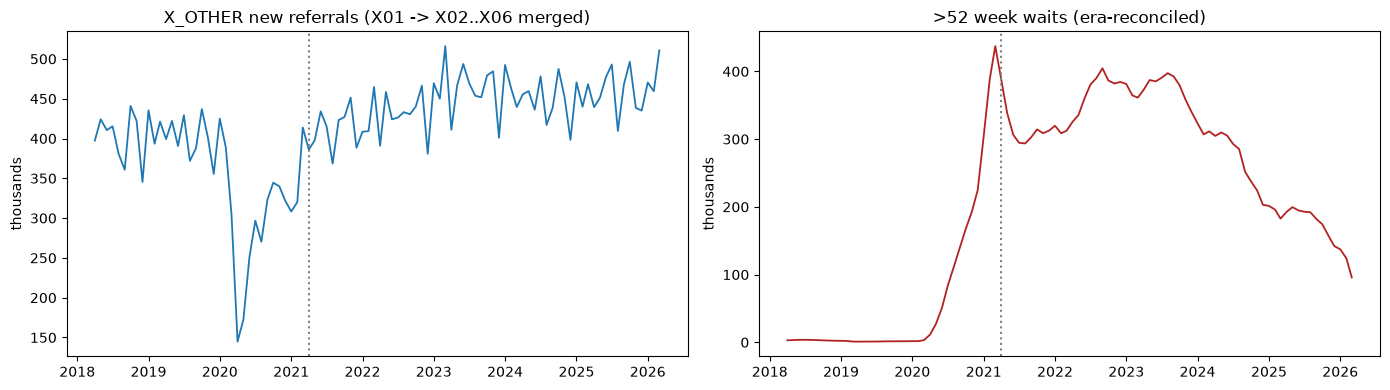

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(other_demand.index, other_demand / 1e3, lw=1.3)
ax[0].axvline(ERA, color="grey", ls=":")                       # the recode boundary
ax[0].set_title("X_OTHER new referrals (X01 -> X02..X06 merged)")
ax[0].set_ylabel("thousands")
ax[1].plot(gt52_waiting.index, gt52_waiting / 1e3, lw=1.3, color="firebrick")
ax[1].axvline(ERA, color="grey", ls=":")                       # same boundary, other reconciliation
ax[1].set_title(">52 week waits (era-reconciled)")
ax[1].set_ylabel("thousands")
plt.tight_layout()

## The panel cube

The federation trains on a rectangular 126 × 19 × 96 cube. Cells absent from the source are filled with zero, but **most of that fill is structural** — a trust that does not provide neurosurgery has no neurosurgery rows, ever. Those series are counted and flagged here so phase 3 can exclude them in one line instead of training on constant zeros.

In [11]:
MEASURES = ["demand", "completed_admitted", "completed_nonadmitted", "completed",
            "waiting", "waiting_gt18", "waiting_gt52", "waiting_dta"]

# from_product builds every combination of the given lists - the full (trust, dept, month) grid.
# With .reindex() below, absent cells come back NaN so they are filled deliberately, not by accident.
full = pd.MultiIndex.from_product(
    [sorted(eligible), sorted(canon.dept.unique()), sorted(canon.month.unique())],
    names=["provider_code", "dept", "month"])

panel = (canon[canon.fl_client]                                # federation clients only
         .set_index(["provider_code", "dept", "month"])
         .reindex(full))                                       # absent combinations become NaN rows
filled = int(panel.demand.isna().sum())                        # how many cells were absent
panel[MEASURES] = panel[MEASURES].fillna(0)                    # absent = no activity = 0
panel = panel.reset_index()
panel["sector"] = "public"                                     # public by construction
panel["fl_client"] = True                                      # ditto — reindex left NaN on new rows
panel["allocatable"] = True
panel["icb"] = panel.provider_code.map(                        # re-attach the key the new rows lack
    dict(zip(provider_dim.provider_code, provider_dim.icb)))

print(f"panel cube : {len(panel):,} rows = {len(eligible)} trusts x "
      f"{panel.dept.nunique()} depts x {panel.month.nunique()} months")
print(f"cells filled with zero : {filled:,} ({filled / len(panel) * 100:.2f}% of the cube)")
assert panel.icb.notna().all(), "panel rows without an ICB — the escalation key has holes"

panel cube : 273,600 rows = 150 trusts x 19 depts x 96 months
cells filled with zero : 79,187 (28.94% of the cube)


In [12]:
# how much of that fill is a service that never existed, vs a month that went unreported?
lifetime = panel.groupby(["provider_code", "dept"]).demand.sum()    # total demand per series
never = lifetime.eq(0)                                             # never any activity at all
print(f"trust x dept series in the cube  : {len(lifetime):,}")
print(f"  never any demand (structural)  : {int(never.sum()):,} ({never.mean() * 100:.1f}%)")
print(f"  genuinely active series        : {int((~never).sum()):,}")

# for the active ones, how complete is the history?
active_months = panel[panel.demand > 0].groupby(["provider_code", "dept"]).size()
print(f"  active series: median {active_months.median():.0f}/96 months with demand, "
      f"min {active_months.min()}")

# flag it in the cube so phase 3 filters in one line instead of rediscovering this
keys = list(zip(panel.provider_code, panel.dept))                  # the series each row belongs to
exists = (~never).to_dict()                                        # (provider, dept) -> bool
panel["service_exists"] = [exists[k] for k in keys]
print(f"\nrows flagged service_exists=False: {int((~panel.service_exists).sum()):,}")

# --- attach the reporting flag, so a zero that is really a missing return can be told apart -------
# reported_demand is False when the provider filed something that month but no Part_3 rows, and
# absent entirely when the provider filed nothing at all. Both become False after this merge, and
# both mean "this zero is not evidence of no activity".
rep_key = reporting.rename(columns={"Provider Org Code": "provider_code"})[
    ["provider_code", "month", "reported_demand", "reported_full", "n_parts"]]
before = len(panel)                                                # row count guard: a merge that
panel = panel.merge(rep_key, on=["provider_code", "month"], how="left")   # grows means a bad key
assert len(panel) == before, "reporting merge changed the row count - the key is not unique"
panel["reported_demand"] = panel["reported_demand"].fillna(False).astype(bool)   # absent = no return
panel["reported_full"] = panel["reported_full"].fillna(False).astype(bool)
panel["n_parts"] = panel["n_parts"].fillna(0).astype(int)

# a cell is a TRUSTWORTHY zero only if the service exists AND the provider filed demand that month
panel["usable"] = panel.service_exists & panel.reported_demand
unusable = panel[panel.service_exists & ~panel.reported_demand]    # real service, missing return
print(f"\nrows where the service exists but no Part_3 was filed: {len(unusable):,} "
      f"({len(unusable) / len(panel) * 100:.2f}% of the cube)")
print(f"  affected trust x month combinations : "
      f"{unusable.groupby(['provider_code', 'month']).ngroups:,}")
print(f"  affected trusts                     : {unusable.provider_code.nunique()}")
print(f"rows usable for training (service exists AND demand reported): "
      f"{int(panel.usable.sum()):,} of {len(panel):,}")
print("\nThese zeros are NOT evidence of no activity. Training on them teaches the model that a")
print("real service went to zero, and scoring on them rewards predicting a zero that never")
print("happened. Phase 3 must mask on `usable`, not merely on `service_exists`.")

trust x dept series in the cube  : 2,850
  never any demand (structural)  : 652 (22.9%)
  genuinely active series        : 2,198
  active series: median 96/96 months with demand, min 1



rows flagged service_exists=False: 62,592

rows where the service exists but no Part_3 was filed: 2,866 (1.05% of the cube)
  affected trust x month combinations : 213
  affected trusts                     : 24
rows usable for training (service exists AND demand reported): 208,142 of 273,600

These zeros are NOT evidence of no activity. Training on them teaches the model that a
real service went to zero, and scoring on them rewards predicting a zero that never
happened. Phase 3 must mask on `usable`, not merely on `service_exists`.


## The backlog accounting identity

The README's decision layer assumes `backlog ≈ previous backlog + demand − completions`. That is an approximation: pathways also leave the list without a completion — removals, transfers, validation exercises, deaths, patients who decline. Measuring the residual tells the agent designer the size of the term they would be ignoring.

In [13]:
# NHS calls this quantity "unreported removals": list at start + clock starts - completed - list
# at end [UR]. That is our residual with the sign reversed. Not a novel measurement; what is new is
# reproducing it per trust x specialty, which NHS does not publish.
nat = panel.groupby("month")[["demand", "completed", "waiting"]].sum().sort_index()
# .shift(1) moves a column down one row so row t sees row t-1, which is how the identity reads
# LAST month's backlog. The frame must be sorted by month first or it compares unrelated months.
nat["predicted"] = nat.waiting.shift(1) + nat.demand - nat.completed    # the stated identity
nat["residual"] = nat.waiting - nat.predicted                           # actual minus predicted
nat["unreported_removals"] = -nat.residual                              # NHS's sign convention

# Two denominators: NHS quotes this as a share of TOTAL REMOVALS, this project has quoted it as a
# share of DEMAND. Both are computed, because an unlabelled percentage is not a number.
nat["total_removals"] = nat.completed + nat.unreported_removals         # everything leaving the list
nat["pct_of_removals"] = nat.unreported_removals / nat.total_removals * 100   # NHS's basis
nat["pct_of_demand"] = nat.unreported_removals / nat.demand * 100             # this project's basis
nat["pct_of_list"] = nat.unreported_removals / nat.waiting * 100              # scale of the stock

r = nat.unreported_removals.dropna()                                    # first month has no previous
print(f"months measured               : {len(r)}")
print(f"mean unreported removals      : {r.mean():,.0f} per month")
print(f"positive (identity over-predicts the list) in {int((r > 0).sum())} of {len(r)} months")
print()
# mean-of-ratios and ratio-of-means answer different questions and differ here; state which is which
print("Expressed as a share, both ways round:")
for label, col, denom in [("of total removals", "pct_of_removals", "total_removals"),
                          ("of demand        ", "pct_of_demand", "demand"),
                          ("of waiting list  ", "pct_of_list", "waiting")]:
    mor = nat[col].mean()                                               # mean of the monthly ratios
    rom = r.sum() / nat.loc[r.index, denom].sum() * 100                 # ratio of the summed totals
    print(f"  {label} : mean-of-ratios {mor:6.2f}%   ratio-of-means {rom:6.2f}%")

print()
print("NHS's published figures for comparison, on the TOTAL REMOVALS basis [UR]:")
print("  17% of total removals before the pandemic, 14% since 2021.")
# split our own series on the same boundary NHS uses, so the comparison is like for like
pre = nat.loc[nat.index < '2020-03-01']                                 # before the pandemic
post = nat.loc[nat.index >= '2021-01-01']                               # NHS's "since 2021"
for label, blk in [("ours, pre-pandemic (to Feb-2020)", pre), ("ours, 2021 onward", post)]:
    v = blk.unreported_removals.dropna()
    if len(v):
        print(f"  {label:32s}: {v.sum() / blk.loc[v.index, 'total_removals'].sum() * 100:5.2f}% "
              f"of removals   ({len(v)} months)")

print()
print("What the leak actually is, from NHS's own record-level linkage [UR]: of unreported removals")
print("with a recorded reason in 2025, 49% were patients who STARTED TREATMENT but were recorded")
print("too late to count (providers may only submit removals occurring within the reporting month,")
print("so historic removals are lost to reporting), 23% a decision not to treat, and 11% a DNA at")
print("the first appointment. So this is NOT one attrition rate: about half of it is throughput")
print("that happened. A decision layer modelling it as a single loss term will understate capacity.")

months measured               : 95
mean unreported removals      : 213,380 per month
positive (identity over-predicts the list) in 95 of 95 months

Expressed as a share, both ways round:
  of total removals : mean-of-ratios  15.24%   ratio-of-means  15.28%
  of demand         : mean-of-ratios  15.02%   ratio-of-means  14.91%
  of waiting list   : mean-of-ratios   4.11%   ratio-of-means   3.87%

NHS's published figures for comparison, on the TOTAL REMOVALS basis [UR]:
  17% of total removals before the pandemic, 14% since 2021.
  ours, pre-pandemic (to Feb-2020): 16.91% of removals   (22 months)
  ours, 2021 onward               : 14.81% of removals   (63 months)

What the leak actually is, from NHS's own record-level linkage [UR]: of unreported removals
with a recorded reason in 2025, 49% were patients who STARTED TREATMENT but were recorded
too late to count (providers may only submit removals occurring within the reporting month,
so historic removals are lost to reporting), 23% a dec

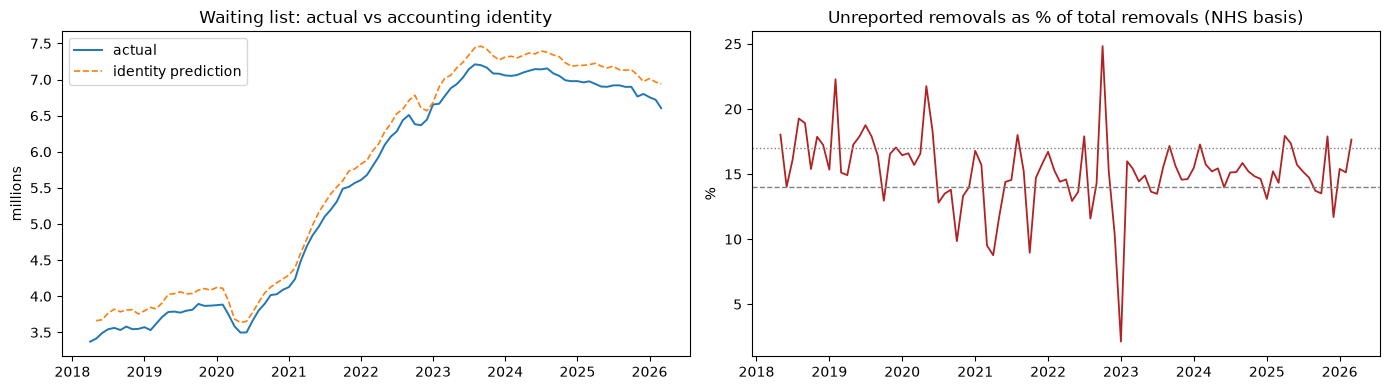

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(nat.index, nat.waiting / 1e6, lw=1.4, label="actual")
ax[0].plot(nat.index, nat.predicted / 1e6, lw=1.2, ls="--", label="identity prediction")
ax[0].set_title("Waiting list: actual vs accounting identity")
ax[0].set_ylabel("millions"); ax[0].legend()

# NHS quotes unreported removals as a share of TOTAL REMOVALS, so plot that basis and draw
# their two published levels on it: 17% before the pandemic, 14% from 2021 [UR].
ax[1].plot(nat.index, nat.pct_of_removals, lw=1.3, color="firebrick")
ax[1].axhline(17, color="grey", ls=":", lw=1)                  # NHS pre-pandemic level
ax[1].axhline(14, color="grey", ls="--", lw=1)                 # NHS level since 2021
ax[1].set_title("Unreported removals as % of total removals (NHS basis)")
ax[1].set_ylabel("%")
plt.tight_layout()

---

# The column contract

The raw return is 69 columns before April 2021 and 121 after. The canonical table keeps **15**. A column earns its place only if some part of the README's system consumes it; everything else is dropped, and the reason is measured here rather than asserted, so the contract can be re-checked if NHS England changes the return again.

## Kept, and what consumes it

| Column | Consumed by |
|---|---|
| `month`, `provider_code`, `dept` | the key — one series per federated client × department |
| `demand` (`Part_3`) | **the forecast target.** New RTT periods = new referrals |
| `completed_admitted`, `completed_nonadmitted` | trailing throughput, split because the README's capacity ask is in treatments per month, admitted vs non-admitted, never literal beds |
| `completed` | their sum; the throughput term in the accounting identity |
| `waiting` (`Part_2`) | backlog stock |
| `waiting_gt18` | the 18-week standard the agent projects against |
| `waiting_gt52` | breach severity — how far past the standard the queue already is |
| `waiting_dta` (`Part_2A`) | the bed-linked admission queue |
| `sector` | independents enter as purchasable substitution capacity, not as clients |
| `icb` | the escalation key: trust → ICB → national |
| `fl_client` | selects the 126 federation clients — trains the forecaster |
| `allocatable` | can receive NHS capacity: public providers only. Independents are bought from, not allocated to |

## Dropped, with the measurement that justifies it

| Dropped | Why |
|---|---|
| `Total` | populated **only** for the two completed part types; identically zero for `Part_2`, `Part_2A` and `Part_3`. `Total All` is the only headline column populated for all five. |
| `Patients with unknown clock start date` | 0.006% of `Total All`, and already inside it. No decision turns on 6 patients in 100,000. |
| `Commissioner Org/Parent Code` + names | a *second* hierarchy — who pays — orthogonal to the README's provider → ICB → national escalation. Collapsing it is what turns ~145,000 raw rows per month into ~16,000 provider × dept × part groups, and Assert 1 passes *after* that collapse, so no provider-level information is lost. |
| `Provider Parent Name`, `Commissioner *Name`, `RTT Part Description`, `Treatment Function Name` | labels for codes already carried. F-11 proved the names are **unstable** across the 2021 break while the codes are not, so carrying them is an active hazard, not redundancy. |
| bands 0–18 weeks | within-standard waits. The operational state is the breach count, not the shape of the compliant queue. |
| bands on `Part_1A/1B/2A/3` | `Part_3` has **no** populated bands at all (F-03). For the completed parts the bands describe realised wait, which is a plausible future feature but is in no README state variable — dropped deliberately, recoverable from raw. |
| `provider_name` | one value per code, 30 MB of a 170 MB table. Moved to `provider_dim.csv`, where a per-provider attribute belongs. |
| `icb_reported`, `icb_ods` | superseded by the single resolved `icb`. Provenance kept in `provider_dim.csv`. |
| `in_roster` | exactly `dept != X_OTHER`. Two ways to express one fact is two ways to disagree. |

`completed` is kept although it is exactly `admitted + nonadmitted`: it is a measure the README names directly, and precomputing the model-facing quantity is the point of a canonical table. The rule is *drop derivable flags, keep derived measures*.

In [15]:
# Evidence for the drops. One file per era, read in full — the contract is a claim about
# every column, so this is the one place the discarded columns are actually looked at.
for label, p in [("pre-2021", csvs[0]), ("post-2021", csvs[-1])]:
    d = pd.read_csv(p, low_memory=False)                       # whole file, all 69 or 121 columns
    d = d[d["Treatment Function Code"] != AGG]                 # published aggregate rows are not data
    bands = [c for c in d.columns if "Weeks SUM" in c]         # every waiting-time band this era has
    d[bands] = d[bands].fillna(0)                              # a blank band means no patients
    d["bandsum"] = d[bands].sum(axis=1)                        # patients accounted for by the bands

    print(f"=== {label}: {p.name}")
    print(f"    {len(d.columns) - len(bands)} descriptive/headline columns + {len(bands)} bands")

    # (1) is 'Total' ever needed, or does 'Total All' carry everything?
    t = d.groupby("RTT Part Type")[["Total", "Total All", "bandsum"]].sum()
    t["Total/TotalAll"] = (t["Total"] / t["Total All"]).round(4)      # 0 = column is empty here
    t["bands/TotalAll"] = (t["bandsum"] / t["Total All"]).round(4)    # 0 = part type has no bands
    print(t.to_string(float_format=lambda v: f"{v:,.0f}"))

    # (2) how much sits in the unknown-clock-start column that we never read
    unk = d["Patients with unknown clock start date"].fillna(0)
    print(f"    unknown clock start: {unk.sum():,.0f} = "
          f"{100 * unk.sum() / d['Total All'].sum():.4f}% of Total All, and already inside it")

    # (3) what the commissioner axis costs. ngroups is the number of groups a groupby would
    #     produce without materialising them — the row count our build collapses to.
    g = d.groupby(["Provider Org Code", "Treatment Function Code", "RTT Part Type"]).ngroups
    print(f"    rows {len(d):,} -> provider x tf x part {g:,}  "
          f"(the commissioner axis is a {len(d) / g:.1f}x row multiplier)")
    print()

# (4) names are unstable, codes are not — why every join in this notebook is on code
n_pre = pd.read_csv(csvs[0], usecols=["Treatment Function Code", "Treatment Function Name"])
n_post = pd.read_csv(csvs[-1], usecols=["Treatment Function Code", "Treatment Function Name"])
name = lambda d: dict(zip(d["Treatment Function Code"], d["Treatment Function Name"]))
a, b = name(n_pre), name(n_post)
changed = [k for k in a if k in b and a[k] != b[k]]            # same code, different label
print(f"treatment function codes present in both eras : {len(set(a) & set(b))}")
print(f"  of those, RENAMED across the break          : {len(changed)}")
print(f"  example: {changed[0]} '{a[changed[0]]}' -> '{b[changed[0]]}'")

=== pre-2021: RTT-April-2018-full-extract-revised.csv
    17 descriptive/headline columns + 53 bands
                  Total  Total All   bandsum  Total/TotalAll  bands/TotalAll
RTT Part Type                                                               
Part_1A         286,943     287031   286,943               1               1
Part_1B       1,006,862    1007247 1,006,862               1               1
Part_2                0    4037223 4,037,223               0               1
Part_2A               0     750564   750,564               0               1
Part_3                0    1646372         0               0               0
    unknown clock start: 473 = 0.0061% of Total All, and already inside it
    rows 151,746 -> provider x tf x part 15,762  (the commissioner axis is a 9.6x row multiplier)



C:\Users\heave\AppData\Local\Temp\ipykernel_12356\1066691469.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d["bandsum"] = d[bands].sum(axis=1)                        # patients accounted for by the bands


=== post-2021: 20260331-RTT-March-2026-full-extract-revised.csv
    17 descriptive/headline columns + 105 bands
                  Total  Total All   bandsum  Total/TotalAll  bands/TotalAll
RTT Part Type                                                               
Part_1A         320,415     320541   320,415               1               1
Part_1B       1,374,620    1375272 1,374,620               1               1
Part_2                0    7045510 7,045,510               0               1
Part_2A               0    1178492 1,178,492               0               1
Part_3                0    1932318         0               0               0
    unknown clock start: 778 = 0.0066% of Total All, and already inside it
    rows 143,342 -> provider x tf x part 16,363  (the commissioner axis is a 8.8x row multiplier)



treatment function codes present in both eras : 19
  of those, RENAMED across the break          : 18
  example: C_100 'General Surgery' -> 'General Surgery Service'


## Why `icb_reported` cannot be the escalation key

The RTT file states a `Provider Parent Org Code`, and it is tempting to treat it as the trust's ICB. It is not: it is whatever parent existed *that month*, and the parent organisation of an English trust changed identity twice inside our window — regions until 2019, STPs/ICSs from 2020, statutory ICBs from July 2022.

The test is agreement against `icb_ods`, the parent resolved from the ODS `RE5` "is commissioned by" relationship, which is a single present-day value per trust. If the reported parent were an ICB throughout, agreement would be near 100% in every year.

In [16]:
# only public providers have both columns — independents have no ODS commissioner parent
both = icb_audit.dropna(subset=["icb_ods"])
# .dt.to_period("Y") turns a timestamp into a year-granularity period, so all months of a
# year collapse into one grouping key without any string formatting
yr = both.groupby(both.month.dt.to_period("Y")).apply(
    lambda d: pd.Series({
        "rows": len(d),
        "distinct_reported": d.icb_reported.nunique(),           # 14 = regions, 42 = ICBs
        "agree_with_ods_pct": round((d.icb_reported == d.icb_ods).mean() * 100, 1),
    }), include_groups=False)                                    # exclude the key from the lambda's frame
print(yr.to_string())
print()
print("2018-19: 14 distinct parents, 0% agreement — the reported parent is an NHS REGION,")
print("a different level of the hierarchy entirely. From 2020 it is 42 ICBs agreeing ~74%;")
print("the residual 26% is real drift between the file and ODS. Neither era is safe as a key,")
print("so `icb` comes from ODS and is backfilled only where ODS has no answer.")
print()
print(f"resolved icb: {canon.icb.nunique()} distinct | "
      f"panel trusts covered {canon[canon.fl_client].icb.notna().mean() * 100:.0f}%")

          rows  distinct_reported  agree_with_ods_pct
month                                                
2018   19205.0               14.0                 0.0
2019   25971.0               14.0                 0.0
2020   25981.0               56.0                56.2
2021   25815.0               42.0                74.2
2022   25610.0               42.0                73.8
2023   25548.0               42.0                72.8
2024   25098.0               42.0                72.8
2025   24630.0               42.0                73.8
2026    6124.0               42.0                74.1

2018-19: 14 distinct parents, 0% agreement — the reported parent is an NHS REGION,
a different level of the hierarchy entirely. From 2020 it is 42 ICBs agreeing ~74%;
the residual 26% is real drift between the file and ODS. Neither era is safe as a key,
so `icb` comes from ODS and is backfilled only where ODS has no answer.

resolved icb: 36 distinct | panel trusts covered 100%


---

# Write the outputs

The 96 monthly extracts, 7.7 GB of raw CSV, collapse to **one** RTT table on the contract above.

| File | What it is |
|---|---|
| `rtt_canonical.parquet` | **the merged RTT table** — every provider × department × month, 14 columns |
| `rtt_canonical.csv.gz` | the same table as text, for anything that cannot read parquet |
| `rtt_panel.parquet` | the rectangular 126 × 19 × 96 federation cube |
| `provider_dim.csv` | one row per provider: name, sector, ICB, panel membership, ICB provenance |
| `national_monthly.csv` | national series plus the accounting-identity residual |

Parquet is the primary format because it stores column types and compresses each column separately, so `month` comes back as a datetime rather than a string and the file is a fraction of the CSV size. The gzipped CSV is a convenience copy, not the source of truth.

In [17]:
# These are pathway counts, so integers. They are float64 only because the pivot and reindex
# introduced NaNs that were then filled, and a column that has held a NaN stays float.
MEASURES_INT = ['demand', 'completed_admitted', 'completed_nonadmitted', 'completed',
                'waiting', 'waiting_gt18', 'waiting_gt52', 'waiting_dta']
assert canon[MEASURES_INT].notna().all().all(), 'a measure is NaN - do not cast, find out why'
assert (canon[MEASURES_INT] % 1 == 0).all().all(), 'a measure is fractional - not a count'
canon[MEASURES_INT] = canon[MEASURES_INT].astype('int64')      # counts, not quantities

# Sort for reading: month first, so the file opens at Apr-2018 and reads chronologically.
# The build order was provider-first, which is why row 1 was an independent clinic in 2024.
canon = canon.sort_values(['month', 'provider_code', 'dept']).reset_index(drop=True)

canon.to_parquet(OUT / "rtt_canonical.parquet", index=False)   # the merged RTT table
canon.to_csv(OUT / "rtt_canonical.csv", index=False)           # the same table, literal single CSV
# same reasoning as the canonical table: these are counts, and the cube is read by month
PANEL_INT = ['demand', 'completed_admitted', 'completed_nonadmitted', 'completed',
             'waiting', 'waiting_gt18', 'waiting_gt52', 'waiting_dta']
panel[PANEL_INT] = panel[PANEL_INT].astype('int64')
panel = panel.sort_values(['month', 'provider_code', 'dept']).reset_index(drop=True)

panel.to_parquet(OUT / "rtt_panel.parquet", index=False)       # rectangular 126 x 19 x 96 cube
provider_dim.to_csv(OUT / "provider_dim.csv", index=False)     # per-provider attributes
nat.to_csv(OUT / "national_monthly.csv")                       # national series + identity check

raw_bytes = sum(f.stat().st_size for f in csvs)                # the 96 source extracts
for f in sorted(OUT.glob("*")):
    print(f"{f.name:26s} {f.stat().st_size / 1e6:8.1f} MB")
print(f"\n{len(csvs)} raw extracts {raw_bytes / 1e9:.1f} GB -> one table "
      f"{(OUT / 'rtt_canonical.csv').stat().st_size / 1e6:.1f} MB as CSV "
      f"({raw_bytes / (OUT / 'rtt_canonical.csv').stat().st_size:,.0f}x smaller)")

print("\ncanonical schema:")
print(canon.dtypes.to_string())

# read both formats straight back: a written file that cannot be read is not an output
check = pd.read_parquet(OUT / "rtt_canonical.parquet")
assert check.shape == canon.shape, "parquet round-trip changed the table's shape"
assert check.month.dtype.kind == "M", "month did not survive as a datetime"   # 'M' = datetime64
csv_back = pd.read_csv(OUT / "rtt_canonical.csv")
assert csv_back.shape == canon.shape, "csv round-trip changed the table's shape"
assert abs(csv_back.demand.sum() - canon.demand.sum()) < 1, "csv round-trip lost demand"
print(f"\nround-trip OK (parquet + csv): {check.shape[0]:,} x {check.shape[1]} columns, "
      f"months {check.month.min():%Y-%m} to {check.month.max():%Y-%m}")

print("\nown-ICB share — how literally the trust -> ICB escalation can be taken (F-22):")
oi = provider_dim[provider_dim.allocatable].own_icb_share.dropna()
print(oi.describe().round(1).to_string())
print(f"public providers below 50%: {int((oi < 50).sum())} of {len(oi)} — "
      f"national specialist centres, which draw referrals from many ICBs")

baselines.csv                   0.0 MB
baselines_by_horizon.csv        0.0 MB
national_monthly.csv            0.0 MB
provider_dim.csv                0.1 MB
rtt_canonical.csv              23.2 MB
rtt_canonical.parquet           4.2 MB
rtt_panel.parquet               3.0 MB
series_index.csv                0.1 MB

96 raw extracts 8.2 GB -> one table 23.2 MB as CSV (354x smaller)

canonical schema:
month                    datetime64[us]
provider_code                       str
dept                                str
sector                              str
icb                                 str
fl_client                          bool
allocatable                        bool
demand                            int64
completed_admitted                int64
completed_nonadmitted             int64
completed                         int64
waiting                           int64
waiting_gt18                      int64
waiting_gt52                      int64
waiting_dta                       int64



round-trip OK (parquet + csv): 322,531 x 15 columns, months 2018-04 to 2026-03

own-ICB share — how literally the trust -> ICB escalation can be taken (F-22):
count    173.0
mean      82.7
std       20.6
min        0.0
25%       77.4
50%       89.9
75%       96.8
max      100.0
public providers below 50%: 12 of 173 — national specialist centres, which draw referrals from many ICBs
